[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tayalmanan28/MuJoCo-Tutorial/blob/main/tutorial/08_gymnasium.ipynb)

# Tutorial 8: MuJoCo + Gymnasium (RL Environments)

Use MuJoCo environments for reinforcement learning with Gymnasium.

In [1]:
!pip install -q mujoco gymnasium[mujoco] mediapy matplotlib

In [2]:
import os
# 关键：必须在导入 mujoco、gymnasium 之前设置，强制使用 EGL 硬件加速离屏渲染
os.environ["MUJOCO_GL"] = "egl"
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import mediapy as media

## Built-in MuJoCo Environments

Gymnasium ships with classic MuJoCo control tasks:

In [3]:
# List available MuJoCo environments
mujoco_envs = [e for e in gym.envs.registry.keys() if 'v5' in e and any(
    name in e for name in ['Ant', 'HalfCheetah', 'Hopper', 'Humanoid', 'Walker', 'Swimmer', 'Reacher', 'Pendulum', 'Inverted']
)]
print("MuJoCo v5 environments:")
for e in sorted(mujoco_envs)[:12]:
    print(f"  {e}")

MuJoCo v5 environments:
  Ant-v5
  HalfCheetah-v5
  Hopper-v5
  Humanoid-v5
  HumanoidStandup-v5
  InvertedDoublePendulum-v5
  InvertedPendulum-v5
  Reacher-v5
  Swimmer-v5
  Walker2d-v5


In [4]:
# Create environment with RGB rendering
env = gym.make('InvertedPendulum-v5', render_mode='rgb_array')
obs, info = env.reset(seed=42)

print(f"Observation shape: {obs.shape}")
print(f"Action space: {env.action_space}")
print(f"Observation: {obs}")

Observation shape: (4,)
Action space: Box(-3.0, 3.0, (1,), float32)
Observation: [ 0.00547912 -0.00122243  0.00717196  0.00394736]


## Running an Episode

In [11]:
frames = []
obs, info = env.reset(seed=42)
total_reward = 0

for step in range(200):
    # Simple proportional controller (not RL — just to show the env working)
    # obs[1] is pole angle, obs[3] is pole angular velocity
    action = np.array([10.0 * obs[1] + 2.0 * obs[3]])
    action = np.clip(action, env.action_space.low, env.action_space.high)

    obs, reward, terminated, truncated, info = env.step(action)
    total_reward += reward

    if step % 3 == 0:
        frames.append(env.render())

    if terminated or truncated:
        break

env.close()
print(f"Episode: {step+1} steps, reward: {total_reward:.1f}")
media.show_video(frames, fps=20)

Episode: 113 steps, reward: 218.2


"<source src=""data:video/mp4;base64,AAAAIGZ0eXBpc29tAAACAGlzb21pc28yYXZjMW1wNDEAAAAIZnJlZQAABaBtZGF0AAACfwYF//973EXpvebZSLeWLNgg2SPu73gyNjQgLSBjb3JlIDE2NCByMzEwOCAzMWUxOWY5IC0gSC4yNjQvTVBFRy00IEFWQyBjb2RlYyAtIENvcHlsZWZ0IDIwMDMtMjAyMyAtIGh0dHA6Ly93d3cudmlkZW9sYW4ub3JnL3gyNjQuaHRtbCAtIG9wdGlvbnM6IGNhYmFjPTEgcmVmPTMgZGVibG9jaz0xOjA6MCBhbmFseXNlPTB4MzoweDExMyBtZT1oZXggc3VibWU9NyBwc3k9MSBwc3lfcmQ9MS4wMDowLjAwIG1peGVkX3JlZj0xIG1lX3JhbmdlPTE2IGNocm9tYV9tZT0xIHRyZWxsaXM9MSA4eDhkY3Q9MSBjcW09MCBkZWFkem9uZT0yMSwxMSBmYXN0X3Bza2lwPTEgY2hyb21hX3FwX29mZnNldD0tMiB0aHJlYWRzPTMgbG9va2FoZWFkX3RocmVhZHM9MSBzbGljZWRfdGhyZWFkcz0wIG5yPTAgZGVjaW1hdGU9MSBpbnRlcmxhY2VkPTAgYmx1cmF5X2NvbXBhdD0wIGNvbnN0cmFpbmVkX2ludHJhPTAgYmZyYW1lcz0zIGJfcHlyYW1pZD0yIGJfYWRhcHQ9MSBiX2JpYXM9MCBkaXJlY3Q9MSB3ZWlnaHRiPTEgb3Blbl9nb3A9MCB3ZWlnaHRwPTIga2V5aW50PTI1MCBrZXlpbnRfbWluPTIwIHNjZW5lY3V0PTQwIGludHJhX3JlZnJlc2g9MCByYz1jcXAgbWJ0cmVlPTAgcXA9MjAgaXBfcmF0aW89MS40MCBwYl9yYXRpbz0xLjMwIGFxPTAAgAAAAFVliIQA//70oPgU0GJjysxWvdiImDlA4OycM4dgAAADAAAf0Yzmi/PcDnyAABFgAQwaVN1YW92MxUr1VPKXAAADAAADAAADAAADAAADAAADAAADAD0hAAAADkGaJGx/5EAAAAMAACggAAAADEGeQnivAAADAAAO6QAAAA0BnmF0Sf8AAAMAABFwAAAADQGeY2pJ/wAAAwAAEXEAAAAUQZpoSahBaJlMD//kQAAAAwAAKCEAAAAOQZ6GRREtfwAAAwAADukAAAANAZ6ldEn/AAADAAARcQAAAA0BnqdqSf8AAAMAABFwAAAAFEGarEmoQWyZTA//5EAAAAMAACggAAAADkGeykUVLX8AAAMAAA7pAAAADQGe6XRJ/wAAAwAAEXAAAAANAZ7rakn/AAADAAARcAAAABRBmvBJqEFsmUwP/+RAAAADAAAoIQAAAA5Bnw5FFS1/AAADAAAO6QAAAA0Bny10Sf8AAAMAABFxAAAADQGfL2pJ/wAAAwAAEXAAAAAUQZs0SahBbJlMD//kQAAAAwAAKCAAAAAOQZ9SRRUtfwAAAwAADukAAAANAZ9xdEn/AAADAAARcAAAAA0Bn3NqSf8AAAMAABFwAAAAFEGbeEmoQWyZTA//5EAAAAMAACghAAAADkGflkUVLX8AAAMAAA7oAAAADQGftXRJ/wAAAwAAEXEAAAANAZ+3akn/AAADAAARcQAAABRBm7xJqEFsmUwP/+RAAAADAAAoIAAAAA5Bn9pFFS1/AAADAAAO6QAAAA0Bn/l0Sf8AAAMAABFwAAAADQGf+2pJ/wAAAwAAEXEAAAAUQZvgSahBbJlMD//kQAAAAwAAKCEAAAAOQZ4eRRUtfwAAAwAADugAAAANAZ49dEn/AAADAAARcAAAAA0Bnj9qSf8AAAMAABFxAAAAFEGaJEmoQWyZTA//5EAAAAMAACggAAAADkGeQkUVLX8AAAMAAA7pAAAADQGeYXRJ/wAAAwAAEXAAAAANAZ5jakn/AAADAAARcQAAABRBmmVJqEFsmUwP/+RAAAADAAAoIQAABPJtb292AAAAbG12aGQAAAAAAAAAAAAAAAAAAAPoAAAHbAABAAABAAAAAAAAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAEAAAAAAAAAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAACAAAEHHRyYWsAAABcdGtoZAAAAAMAAAAAAAAAAAAAAAEAAAAAAAAHbAAAAAAAAAAAAAAAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAEAAAAAAAAAAAAAAAAAAEAAAAAB4AAAAeAAAAAAACRlZHRzAAAAHGVsc3QAAAAAAAAAAQAAB2wAAAQAAAEAAAAAA5RtZGlhAAAAIG1kaGQAAAAAAAAAAAAAAAAAACgAAABMAFXEAAAAAAAtaGRscgAAAAAAAAAAdmlkZQAAAAAAAAAAAAAAAFZpZGVvSGFuZGxlcgAAAAM/bWluZgAAABR2bWhkAAAAAQAAAAAAAAAAAAAAJGRpbmYAAAAcZHJlZgAAAAAAAAABAAAADHVybCAAAAABAAAC/3N0YmwAAACvc3RzZAAAAAAAAAABAAAAn2F2YzEAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAB4AHgAEgAAABIAAAAAAAAAAEVTGF2YzYwLjMxLjEwMiBsaWJ4MjY0AAAAAAAAAAAAAAAY//8AAAA1YXZjQwFkABb/4QAYZ2QAFqzZQeD2hAAAAwAEAAADAKA8WLZYAQAGaOvhssiw/fj4AAAAABRidHJ0AAAAAAAAF40AABeNAAAAGHN0dHMAAAAAAAAAAQAAACYAAAIAAAAAFHN0c3MAAAAAAAAAAQAAAAEAAAFAY3R0cwAAAAAAAAAmAAAAAQAABAAAAAABAAAKAAAAAAEAAAQAAAAAAQAAAAAAAAABAAACAAAAAAEAAAoAAAAAAQAABAAAAAABAAAAAAAAAAEAAAIAAAAAAQAACgAAAAABAAAEAAAAAAEAAAAAAAAAAQAAAgAAAAABAAAKAAAAAAEAAAQAAAAAAQAAAAAAAAABAAACAAAAAAEAAAoAAAAAAQAABAAAAAABAAAAAAAAAAEAAAIAAAAAAQAACgAAAAABAAAEAAAAAAEAAAAAAAAAAQAAAgAAAAABAAAKAAAAAAEAAAQAAAAAAQAAAAAAAAABAAACAAAAAAEAAAoAAAAAAQAABAAAAAABAAAAAAAAAAEAAAIAAAAAAQAACgAAAAABAAAEAAAAAAEAAAAAAAAAAQAAAgAAAAABAAAEAAAAABxzdHNjAAAAAAAAAAEAAAABAAAAJgAAAAEAAACsc3RzegAAAAAAAAAAAAAAJgAAAtwAAAASAAAAEAAAABEAAAARAAAAGAAAABIAAAARAAAAEQAAABgAAAASAAAAEQAAABEAAAAYAAAAEgAAABEAAAARAAAAGAAAABIAAAARAAAAEQAAABgAAAASAAAAEQAAABEAAAAYAAAAEgAAABEAAAARAAAAGAAAABIAAAARAAAAEQAAABgAAAASAAAAEQAAABEAAAAYAAAAFHN0Y28AAAAAAAAAAQAAADAAAABidWR0YQAAAFptZXRhAAAAAAAAACFoZGxyAAAAAAAAAABtZGlyYXBwbAAAAAAAAAAAAAAAAC1pbHN0AAAAJal0b28AAAAdZGF0YQAAAAEAAAAATGF2ZjYwLjE2LjEwMA=="" type=""video/mp4""/> This browser does not support the video tag."


## Comparing Environments

HalfCheetah-v5,Ant-v5,Hopper-v5,Walker2d-v5

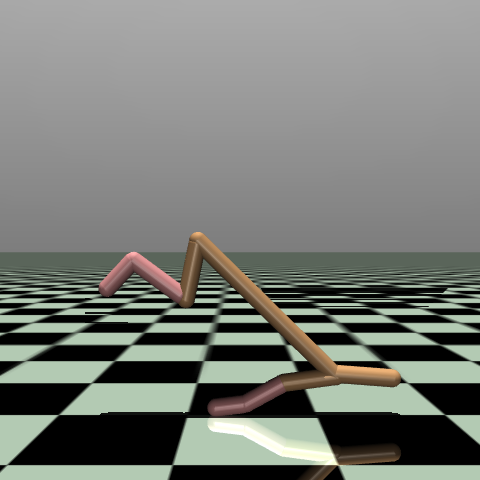
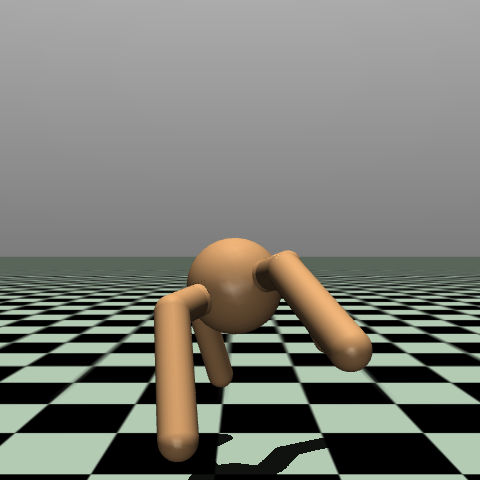
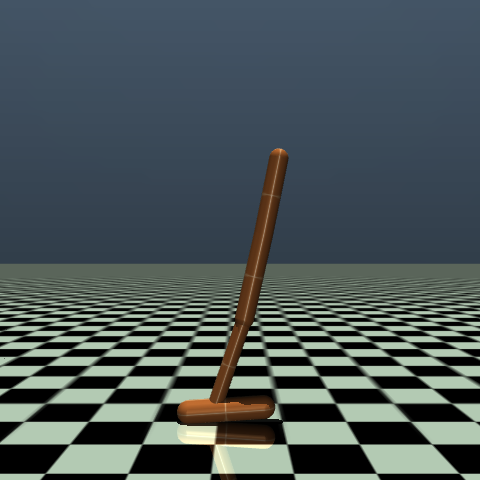
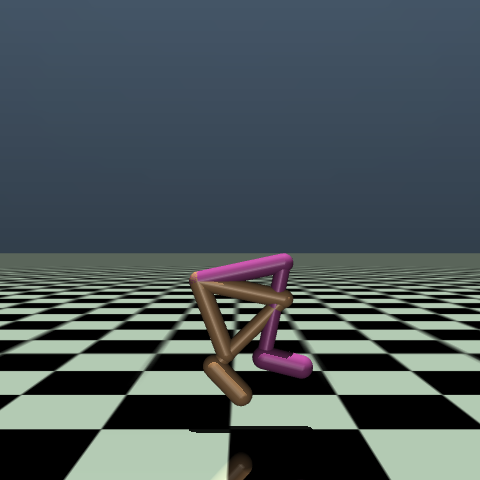

In [12]:
env_names = ['HalfCheetah-v5', 'Ant-v5', 'Hopper-v5', 'Walker2d-v5']
images = []

for name in env_names:
    env = gym.make(name, render_mode='rgb_array')
    env.reset(seed=0)
    # Step a few times so it's not in default pose
    for _ in range(50):
        env.step(env.action_space.sample())
    images.append(env.render())
    env.close()

media.show_images(images, titles=env_names)

## Creating a Custom MuJoCo Gymnasium Environment

Subclass `gymnasium.Env` and use MuJoCo internally:

In [21]:
import mujoco
from gymnasium import spaces

class SimplePendulumEnv(gym.Env):
    """Custom MuJoCo pendulum environment."""
    metadata = {'render_modes': ['rgb_array'], 'render_fps': 30}

    XML = """
    <mujoco>
      <option gravity="0 0 -9.81" timestep="0.02"/>
      <worldbody>
        <light pos="0 0 2"/>
        <body pos="0 0 1">
          <joint name="hinge" type="hinge" axis="0 1 0"/>
          <geom type="capsule" fromto="0 0 0 0 0 -0.5" size="0.04" mass="1" rgba="0 0.7 0 1"/>
        </body>
      </worldbody>
      <actuator>
        <motor joint="hinge" ctrlrange="-3 3"/>
      </actuator>
    </mujoco>
    """

    def __init__(self, render_mode=None):
        self.model = mujoco.MjModel.from_xml_string(self.XML)
        self.data = mujoco.MjData(self.model)
        self.render_mode = render_mode

        # Observation: [cos(angle), sin(angle), angular_velocity]
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(3,), dtype=np.float32)
        self.action_space = spaces.Box(-3.0, 3.0, shape=(1,), dtype=np.float32)

        if render_mode == 'rgb_array':
            self.renderer = mujoco.Renderer(self.model, height=240, width=240)

    def reset(self, seed=None, **kwargs):
        super().reset(seed=seed)
        mujoco.mj_resetData(self.model, self.data)
        # Random initial angle
        self.data.qpos[0] = self.np_random.uniform(-np.pi, np.pi)
        mujoco.mj_forward(self.model, self.data)
        return self._get_obs(), {}

    def step(self, action):
        self.data.ctrl[0] = action[0]
        mujoco.mj_step(self.model, self.data)

        obs = self._get_obs()
        # Reward: upright position
        angle = self.data.qpos[0]
        reward = np.cos(angle) - 0.1 * action[0]**2

        return obs, float(reward), False, False, {}

    def _get_obs(self):
        angle = self.data.qpos[0]
        return np.array([np.cos(angle), np.sin(angle), self.data.qvel[0]], dtype=np.float32)

    def render(self):
        if self.render_mode == 'rgb_array':
            self.renderer.update_scene(self.data)
            return self.renderer.render()

# Test it
env = SimplePendulumEnv(render_mode='rgb_array')
obs, _ = env.reset(seed=0)
print(f"Initial obs: {obs}")

frames = []
for _ in range(1000):
    action = env.action_space.sample()
    obs, reward, _, _, _ = env.step(action)
    frames.append(env.render())

media.show_video(frames, fps=30)
print("Custom environment works!")

Initial obs: [0.6520163 0.758205  0.       ]


This browser does not support the video tag.


Custom environment works!


## Next Steps

- Train an RL agent with [Stable-Baselines3](https://stable-baselines3.readthedocs.io/)
- Use [MJX](./07_mjx.ipynb) for GPU-parallel training
- Build complex environments with multiple bodies/sensors
- Add reward shaping and curriculum learning